# Running the outer optimization: `train_outer_optimization_distributed`

Demonstrates `train_outer_optimization_distributed` (`src/optimize.jl`): the stochastic outer loop
that jointly optimizes `geoms`, `α`, and `β` against the expected reconstruction error, resampling
a fresh random `object`/`noise` and cold-starting the inner reconstruction every iteration. Run for
`opthp.maxeval = 3` outer iterations here -- just enough to see the mechanics (history logging,
clamping, `geoms` actually moving) without a long run. Same production-scale `php`/`imghp` as
`2026-10-14-add-PSF-scale.ipynb`, and the same `rechp`/noise settings as `scripts/time_pipeline.jl`.

In [1]:
cd("../../End2EndThermalImg")
import Pkg
Pkg.activate(".")

  Activating project at `~/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg`


In [2]:
using Revise
using End2EndThermalImg
using PythonPlot
using Parameters
using Distributed
using LinearAlgebra
using Statistics

## Setup

In [3]:
@time nw = End2EndThermalImg.setup_cluster_workers()
println("nworkers = ", nworkers(), "  workers = ", workers())
println("threads per worker = ", [remotecall_fetch(Threads.nthreads, p) for p in workers()])

      From worker 5:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 5:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 4:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 4:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 3:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 3:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 2:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 2:	└   lock_file = "/Us

In [4]:
# Same hyperparameters as scripts/time_pipeline.jl, except opthp.maxeval = 3 (outer iterations,
# not the inner reconstruction's own maxeval) for this demonstration run.
@time @everywhere begin
    php = PhysicsHyperParams(
        λlb_μm = 8.0,
        λub_μm = 12.0,
        freq_order = 20,
        focal_length_μm = 2.0e4,
        num_unit_cells = 2048,
        unit_cell_length_μm = 4.0,
        pillar_width_lb_μm = 1.8,
        pillar_width_ub_μm = 2.7,
        pillar_width_order = 160,
        pillar_height_μm = 10.0,
        pillar_material = "Si_no_absorption",
        substrate_height_μm = 300.0,
        substrate_material = "Si_no_absorption",
        nG = 1000
    )

    imghp = ImagingHyperParams(
        objN = 32,
        imgN = 128,
        binN = 3,
        sampleN = 1,
        PSF_zlb_μm = -2.1e6,
        PSF_zub_μm = -0.9e6,
        PSF_zlen = 3,
        smoothness_order = 3.0,
        object_type = UniformlyRandomObject(Tlb = 136.15, Tub = 450.15, zlb_μm = -2.0e6, zub_μm = -1.0e6, zlen = 7, php = php),
        noise_type = RelativeNoise(0.2),
        php = php
    )

    opthp = OptimizeHyperParams(
        geoms_init_type = "uniform",
        maxeval = 3,          # outer (geoms, α, β) iterations -- kept small for this demo
        learning_rate = 1e-3,
        save_every = 3        # only takes effect if run_folder is passed to
                               # train_outer_optimization_distributed -- this notebook doesn't
                               # (see the run-train cell), so no files are written either way
    )

    rechp = ReconstructionHyperParams(
        object_init_type = "uniform_offset",
        T_background = 293.15,
        z_middle_μm = -1.5e6,
        algorithm = :LD_LBFGS,
        α_init = 1e-7,
        β_init = 1e-7,
        maxeval = 2000,
        xtol_rel = 0.0,
        ftol_rel = 0.0,
        ftol_abs = 0.0,
        php = php
    )

    jhp = JobHyperParams(
        php = php,
        imghp = imghp,
        opthp = opthp,
        rechp = rechp
    )
end

  0.130332 seconds (101.34 k allocations: 5.621 MiB, 41.93% compilation time)


In [5]:
@time End2EndThermalImg.compute_system_parameters(php, imghp)

[ Info: Computing system parameters
[ Info: Image pixel size = 12.0 μm


  0.459280 seconds (2.22 M allocations: 111.987 MiB, 3.07% gc time, 106.23% compilation time)


[ Info: Metasurface size = 8192.0 μm [0.8192 cm]
[ Info: NA: 0.2006


In [6]:
@time driver_plans_n2f, driver_plans_PSF = End2EndThermalImg.setup_fft_plans_distributed!(php, imghp)

  0.757919 seconds (487.93 k allocations: 416.058 MiB, 1.35% gc time, 13.23% compilation time)


(FFTW.cFFTWPlan[FFTW forward plan for 2528×2528 array of ComplexF64
(dft-rank>=2/1
  (dft-vrank>=1-x2528/1
    (dft-ct-dit/32
      (dftw-direct-32/124 "t2fv_32_neon")
      (dft-vrank>=1-x32/1
        (dft-bluestein-79/160
          (dft-ct-dit/4
            (dftw-direct-4/12 "t2fv_4_neon")
            (dft-ct-dif/4
              (dftw-directsq-4/6-x4 "q1fv_4_neon")
              (dft-vrank>=1-x4/1
                (dft-direct-10-x4 "n1fv_10_neon"))))))))
  (dft-buffered-2528-x8/2528-6
    (dft-vrank>=1-x8/1
      (dft-ct-dit/32
        (dftw-direct-32/124 "t2fv_32_neon")
        (dft-vrank>=1-x32/1
          (dft-bluestein-79/160
            (dft-ct-dit/4
              (dftw-direct-4/12 "t2fv_4_neon")
              (dft-ct-dif/4
                (dftw-directsq-4/6-x4 "q1fv_4_neon")
                (dft-vrank>=1-x4/1
                  (dft-direct-10-x4 "n1fv_10_neon"))))))))
    (dft-r2hc-1
      (rdft-rank0-tiledbuf/2-x8-x2528))
    (dft-nop))), FFTW forward plan for 2528×2528 array of

In [7]:
@time freqs = End2EndThermalImg.get_freq_chebpoints(php)
@time n2f_kernels = End2EndThermalImg.compute_and_broadcast(:n2f_kernels, End2EndThermalImg.get_n2f_kernels, freqs, driver_plans_n2f, php, imghp);

  0.146216 seconds (1.09 M allocations: 53.017 MiB, 4.73% gc time, 99.98% compilation time)
  7.596402 seconds (743.11 k allocations: 4.035 GiB, 6.77% gc time, 4.07% compilation time)


In [8]:
@time @everywhere begin
    surrogates = End2EndThermalImg.load_surrogate_models(php);
    geoms = End2EndThermalImg.initialize_geoms(php, opthp)
    PSF_zcoords = End2EndThermalImg.get_PSF_zcoords(imghp)
    weights = End2EndThermalImg.get_clenshaw_curtis_quadrature_weights(php)
end

  2.237990 seconds (7.35 M allocations: 436.923 MiB, 2.41% gc time, 97.80% compilation time: <1% of which was recompilation)


In [9]:
@time End2EndThermalImg.assign_shard_indices!()
@time End2EndThermalImg.init_resident_incidents!(freqs, PSF_zcoords, php)

  0.021850 seconds (388 allocations: 18.711 KiB, 9.81% compilation time)
  1.909924 seconds (181.66 k allocations: 9.053 MiB, 1.97% compilation time)


## Choose `PSF_scale`

Same approach as `2026-10-14-add-PSF-scale.ipynb`: form a true object's image at a reference
scale, then rescale so `mean(image) = 1`. Computed once, up front -- not part of the training
loop itself (which resamples its own `object`/`noise` every iteration).

In [10]:
reference_scale = 1.0
End2EndThermalImg.update_geoms_and_fftPSFs!(geoms, freqs, php, imghp, reference_scale)
object_reference = End2EndThermalImg.get_object(imghp)
image_reference = End2EndThermalImg.make_image_from_3D_distributed(object_reference, weights, php, imghp)
PSF_scale = End2EndThermalImg.choose_PSF_scale(image_reference, reference_scale; target_mean = 1.0)
println("PSF_scale = ", PSF_scale, "  (mean(image) at reference_scale=1.0 was ", mean(image_reference), ")")
End2EndThermalImg.update_geoms_and_fftPSFs!(geoms, freqs, php, imghp, PSF_scale);

PSF_scale = 2.956324311252775e15  (mean(image) at reference_scale=1.0 was 3.382578819900307e-16)


## Run the outer optimization

`opthp.maxeval = 3` is the only stopping criterion -- each iteration resamples a random
`object`/`noise`, cold-starts the inner reconstruction, solves the adjoint system, and takes one
Adam step. `geoms` is updated directly and clamped back into `[pillar_width_lb, pillar_width_ub]`;
`α`/`β` are updated in log-space (`logα = log(α)`, `logβ = log(β)`) so they stay positive
automatically (via `exp`) with no clamping needed -- see the comment above
`train_outer_optimization_distributed` (`src/optimize.jl`) for why that reparameterization was
necessary (a first run hit NaN without it).

In [11]:
out = End2EndThermalImg.train_outer_optimization_distributed(
    geoms, rechp.α_init, rechp.β_init, freqs, weights, driver_plans_PSF, PSF_zcoords, jhp, PSF_scale;
    verbose = true
)

println("\nfinal α = ", out.α, "  final β = ", out.β)
println("extrema(geoms) = ", extrema(out.geoms), "  bounds = (", php.pillar_width_lb, ", ", php.pillar_width_ub, ")")

┌ Info: Iteration 1
│   entry.L = 0.30612618647537804
│   entry.α = 1.0010004986248533e-7
│   entry.β = 9.999976894343525e-8
│   entry.iteration_time = 177.418974166
│   entry.reconstruction_return_value = :SUCCESS
│   entry.reconstruction_iterations = 158
│   entry.minres_converged = true
└   entry.minres_iterations = 25
┌ Info: Iteration 2
│   entry.L = 0.24709830515485903
│   entry.α = 1.001813081155156e-7
│   entry.β = 9.999860380232874e-8
│   entry.iteration_time = 205.434490667
│   entry.reconstruction_return_value = :SUCCESS
│   entry.reconstruction_iterations = 871
│   entry.minres_converged = true
└   entry.minres_iterations = 104
┌ Info: Iteration 3
│   entry.L = 0.2768663122937856
│   entry.α = 1.0027097251872413e-7
│   entry.β = 9.999777760278007e-8
│   entry.iteration_time = 242.916434833
│   entry.reconstruction_return_value = :SUCCESS
│   entry.reconstruction_iterations = 961
│   entry.minres_converged = true
└   entry.minres_iterations = 122



final α = 1.0027097251872413e-7  final β = 9.999777760278007e-8
extrema(geoms) = (0.23137009121792088, 0.23737990896604563)  bounds = (0.1875, 0.28125000000000006)


## Inspect the history

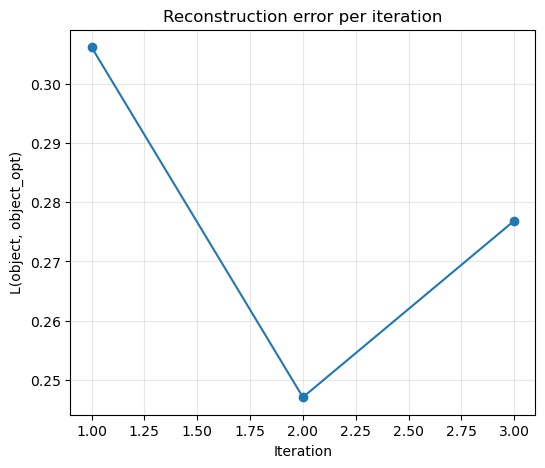

In [12]:
iterations = [e.iteration for e in out.history]
Ls = [e.L for e in out.history]

fig, ax = subplots(figsize=(6, 5))
ax.plot(iterations, Ls, marker="o")
ax.set_xlabel("Iteration")
ax.set_ylabel("L(object, object_opt)")
ax.set_title("Reconstruction error per iteration")
ax.grid(true, alpha=0.3)
fig;

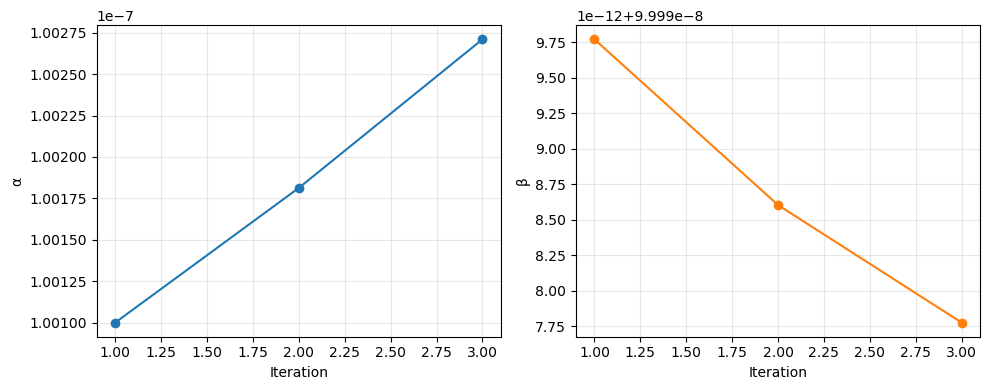

In [13]:
αs = [e.α for e in out.history]
βs = [e.β for e in out.history]

fig, axes = subplots(1, 2; figsize=(10, 4))
axes[0].plot(iterations, αs, marker="o", color="tab:blue")
axes[0].set_xlabel("Iteration")
axes[0].set_ylabel("α")
axes[0].grid(true, alpha=0.3)

axes[1].plot(iterations, βs, marker="o", color="tab:orange")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("β")
axes[1].grid(true, alpha=0.3)

fig.tight_layout()
fig;

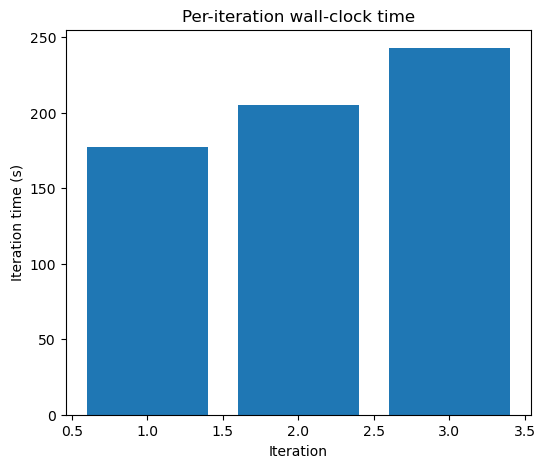

In [14]:
times = [e.iteration_time for e in out.history]

fig, ax = subplots(figsize=(6, 5))
ax.bar(iterations, times)
ax.set_xlabel("Iteration")
ax.set_ylabel("Iteration time (s)")
ax.set_title("Per-iteration wall-clock time")
fig;

In [15]:
for e in out.history
    println("iter $(e.iteration): L=$(e.L)  α=$(e.α)  β=$(e.β)  time=$(e.iteration_time)s",
            "  recon=($(e.reconstruction_return_value), $(e.reconstruction_iterations) iters)",
            "  minres=(converged=$(e.minres_converged), $(e.minres_iterations) iters)")
end

iter 1: L=0.30612618647537804  α=1.0010004986248533e-7  β=9.999976894343525e-8  time=177.418974166s  recon=(SUCCESS, 158 iters)  minres=(converged=true, 25 iters)
iter 2: L=0.24709830515485903  α=1.001813081155156e-7  β=9.999860380232874e-8  time=205.434490667s  recon=(SUCCESS, 871 iters)  minres=(converged=true, 104 iters)
iter 3: L=0.2768663122937856  α=1.0027097251872413e-7  β=9.999777760278007e-8  time=242.916434833s  recon=(SUCCESS, 961 iters)  minres=(converged=true, 122 iters)


## Final `geoms`

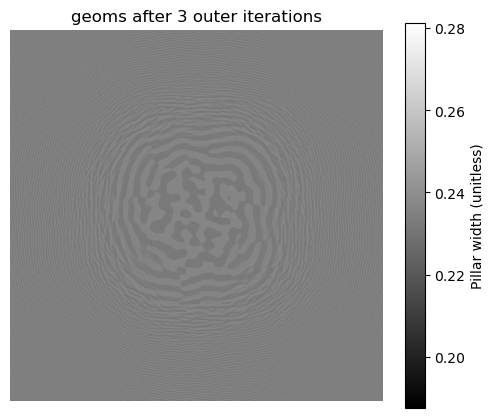

In [16]:
fig, ax = subplots(figsize=(6, 5))
im = ax.imshow(out.geoms, cmap="gray", vmin=php.pillar_width_lb, vmax=php.pillar_width_ub)
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Pillar width (unitless)")
ax.axis("off")
ax.set_title("geoms after $(opthp.maxeval) outer iterations")
fig;

In [18]:
out.history

3-element Vector{NamedTuple}:
 (iteration = 1, L = 0.30612618647537804, α = 1.0010004986248533e-7, β = 9.999976894343525e-8, iteration_time = 177.418974166, reconstruction_return_value = :SUCCESS, reconstruction_iterations = 158, minres_converged = true, minres_iterations = 25)
 (iteration = 2, L = 0.24709830515485903, α = 1.001813081155156e-7, β = 9.999860380232874e-8, iteration_time = 205.434490667, reconstruction_return_value = :SUCCESS, reconstruction_iterations = 871, minres_converged = true, minres_iterations = 104)
 (iteration = 3, L = 0.2768663122937856, α = 1.0027097251872413e-7, β = 9.999777760278007e-8, iteration_time = 242.916434833, reconstruction_return_value = :SUCCESS, reconstruction_iterations = 961, minres_converged = true, minres_iterations = 122)